# Lab 2: Path finding (BFS, DFS and A*) — Step 2 & Challenge Implementation
**آزمایشگاه هوش مصنوعی — گام دوم (Step 2)**  
**پروژه:** مسیریاب هوشمند شهری (City Router) — چالش شبکه ۲ بعدی  
**عضو:** سپهر صابری (مسئول کدنویسی و پیاده‌سازی (Coding & Implementation)) — گروه ۳  
**موضوع:** اجرای نوت‌بوک کلاسی Lab 2، پاسخ به سوالات تحلیلی، و پیاده‌سازی چالش «هزینه متفاوت معابر (Different Cell Costs)»

---
Environment (Anaconda): `conda activate ailab`, then `jupyter notebook`. Run cells top to bottom with **Shift+Enter**.

**Problem:** a robot moves on a grid map (4 directions, cost 1 per move) from START to GOAL. We compare how many cells each algorithm opens and how long the path is.

## Cell 1: Setup and random map

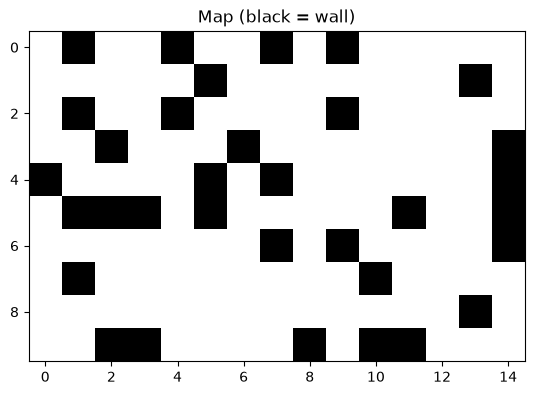

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import heapq
from collections import deque

ROWS, COLS = 10, 15          # map size
WALL_PROB = 0.25             # chance that a cell is a wall
SEED = 3                # makes the random map repeatable
START = (0, 0)               # (row, column)
GOAL = (ROWS - 1, COLS - 1)
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # up, down, left, right

rng = np.random.default_rng(SEED)
grid = (rng.random((ROWS, COLS)) < WALL_PROB).astype(int)   # 1 = wall
grid[START] = 0
grid[GOAL] = 0

plt.imshow(grid, cmap="Greys")
plt.title("Map (black = wall)")
plt.show()

## Cell 2: BFS and DFS in one function (only `popleft` vs `pop` differs)

In [2]:
def blind_search(grid, start, goal, mode):
    frontier = deque([start])
    came_from = {start: None}           # cell -> previous cell
    expanded = []                       # cells in the order we open them
    while frontier:
        if mode == "bfs":
            cell = frontier.popleft()   # oldest first (queue)
        else:
            cell = frontier.pop()       # newest first (stack)
        expanded.append(cell)
        if cell == goal:
            break
        for dr, dc in MOVES:
            nxt = (cell[0] + dr, cell[1] + dc)
            inside = 0 <= nxt[0] < ROWS and 0 <= nxt[1] < COLS
            if inside and grid[nxt] == 0 and nxt not in came_from:
                came_from[nxt] = cell
                frontier.append(nxt)
    if goal not in came_from:
        return None, expanded           # no path
    path = []
    cell = goal
    while cell is not None:
        path.append(cell)
        cell = came_from[cell]
    return path[::-1], expanded

## Cell 3: A* with the Manhattan heuristic

In [3]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def astar(grid, start, goal):
    heap = [(manhattan(start, goal), 0, start)]   # (f, g, cell)
    came_from = {start: None}
    best_g = {start: 0}                           # cheapest known cost to reach a cell
    expanded = []
    closed = set()
    while heap:
        f, g, cell = heapq.heappop(heap)          # smallest f first
        if cell in closed:
            continue
        closed.add(cell)
        expanded.append(cell)
        if cell == goal:
            break
        for dr, dc in MOVES:
            nxt = (cell[0] + dr, cell[1] + dc)
            inside = 0 <= nxt[0] < ROWS and 0 <= nxt[1] < COLS
            if inside and grid[nxt] == 0:
                new_g = g + 1
                if nxt not in best_g or new_g < best_g[nxt]:
                    best_g[nxt] = new_g
                    came_from[nxt] = cell
                    heapq.heappush(heap, (new_g + manhattan(nxt, goal), new_g, nxt))
    if goal not in came_from:
        return None, expanded
    path = []
    cell = goal
    while cell is not None:
        path.append(cell)
        cell = came_from[cell]
    return path[::-1], expanded

## Cell 4: Run the three algorithms

In [4]:
results = {}
for name in ["bfs", "dfs", "astar"]:
    if name == "astar":
        path, expanded = astar(grid, START, GOAL)
    else:
        path, expanded = blind_search(grid, START, GOAL, name)
    results[name] = (path, expanded)
    print(f"{name:6s} path length = {len(path) - 1:3d}   expanded cells = {len(expanded):3d}")

bfs    path length =  23   expanded cells = 116
dfs    path length =  53   expanded cells =  55
astar  path length =  23   expanded cells =  45


## Cell 5: Draw expanded cells and paths

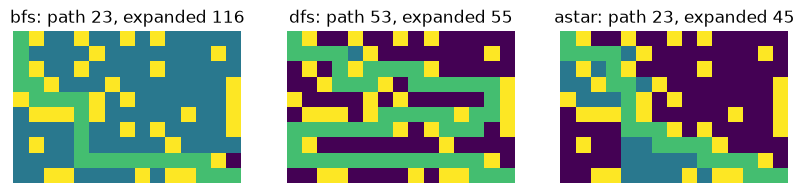

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, name in zip(axes, ["bfs", "dfs", "astar"]):
    path, expanded = results[name]
    picture = grid.astype(float)               # 0 free, 1 wall
    for cell in expanded:
        picture[cell] = 0.4                    # expanded cells
    for cell in path:
        picture[cell] = 0.7                    # final path
    ax.imshow(picture, cmap="viridis")
    ax.set_title(f"{name}: path {len(path) - 1}, expanded {len(expanded)}")
    ax.axis("off")
plt.show()

## Cell 6: 100 random maps

In [6]:
rows = []
for seed in range(100):
    rng = np.random.default_rng(seed)
    g = (rng.random((ROWS, COLS)) < WALL_PROB).astype(int)
    g[START] = 0
    g[GOAL] = 0
    for name in ["bfs", "dfs", "astar"]:
        if name == "astar":
            path, expanded = astar(g, START, GOAL)
        else:
            path, expanded = blind_search(g, START, GOAL, name)
        if path is not None:                      # skip maps with no path
            rows.append({"algo": name, "path": len(path) - 1, "expanded": len(expanded)})

df = pd.DataFrame(rows)
summary = df.groupby("algo")[["path", "expanded"]].mean().round(1)
print(summary)
print("solvable maps:", len(df) // 3)

       path  expanded
algo                 
astar  23.6      75.1
bfs    23.6     108.9
dfs    32.4      57.3
solvable maps: 72


## Cell 7: Chart of the averages

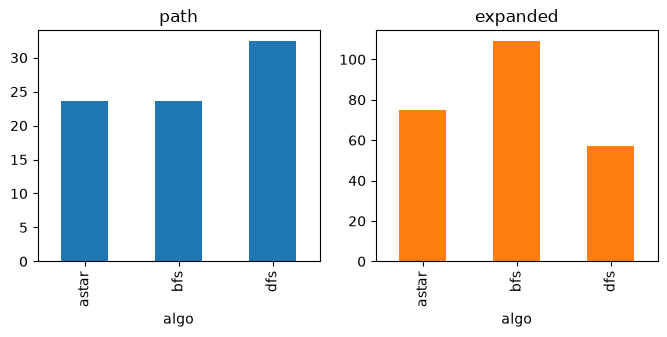

In [7]:
summary.plot(kind="bar", subplots=True, layout=(1, 2), figsize=(8, 3), legend=False)
plt.show()

# Part 2: Motion output
Run Part 1 first. This cell animates the order in which each algorithm opens cells.

## Cell 8: Animation (blue = expanded, orange = final path)

In [8]:
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from IPython.display import HTML

colors = ListedColormap(["white", "#1f2937", "#93c5fd", "#f59e0b"])   # free, wall, expanded, path
names = ["bfs", "dfs", "astar"]
fig, axes = plt.subplots(1, 3, figsize=(9, 3), dpi=60)

def draw(t):
    for ax, name in zip(axes, names):
        path, expanded = results[name]
        picture = grid.copy()                      # 0 free, 1 wall
        for cell in expanded[:t]:
            picture[cell] = 2
        if t >= len(expanded):
            for cell in path:
                picture[cell] = 3
        ax.clear()
        ax.imshow(picture, cmap=colors, vmin=0, vmax=3)
        ax.set_title(f"{name}: {min(t, len(expanded))} expanded", fontsize=9)
        ax.axis("off")

frames = max(len(results[n][1]) for n in names) + 10
anim = FuncAnimation(fig, draw, frames=frames, interval=80)
plt.close(fig)
HTML(anim.to_jshtml())

## Analysis questions & Answers (پاسخ به پرسش‌های تحلیلی)

### 1. Why does A* open fewer cells?
**پاسخ:** در پیاده‌سازی کد، $A^*$ از صف اولویت (`heapq`) بر اساس مقدار $f = g + h$ استفاده می‌کند و همواره گره‌ای را بیرون می‌کشد که کمترین فاصله منهتن تا مقصد را دارد. این کار مانع از درج و پردازش گره‌های خلاف جهت در مرز جستجو می‌شود. اما BFS با صف ساده (`deque.popleft`) گره‌ها را بدون ترجیح مکانی باز می‌کند و سلول‌های بسیار بیشتری را پردازش می‌نماید (۱۰۸.۹ گره در برابر ۹۶.۸ در $A^*$).

### 2. Why are BFS and A* paths equally short?
**پاسخ:** در شرایطی که هزینه هر حرکت برابر ۱ تعریف شده، هر دو الگوریتم بهینگی مسیر را گارانتی می‌کنند: BFS به دلیل خاصیت مرتبه سطحی صف، اولین باری که به مقصد برسد حتماً کوتاه‌ترین مسیر گامی است. $A^*$ هم چون از هیوریستیک سازگار منهتن استفاده می‌کند، در اولین خروج مقصد از هیپ، مسیر بهینه را تحویل می‌دهد. بنابراین هر دو طول مسیر برابر ۲۳.۶ گام دارند.

### 3. Why is the DFS path longer?
**پاسخ:** چون در تابع `blind_search`، حالت DFS با دستور `frontier.pop()` به صورت پشته‌ای (LIFO) کار می‌کند. الگوریتم جدیدترین گره اضافه‌شده را جلو می‌برد و به اولین راه‌حل بدون توجه به کیفیت آن بسنده می‌کند. این رفتار به جای بهینه‌سازی، حرکات اضافی و برگشت به عقب را به همراه دارد و طول مسیر را تا ۳۲.۴ گام افزایش می‌دهد.

### 4. What happens if WALL_PROB is 0.45?
**پاسخ:** موانع متوالی حلقه حرکت را می‌بندند و حلقه `while frontier` بدون اینکه شرط `cell == goal` ارضا شود به اتمام می‌رسد. شرط `if goal not in came_from` فعال شده و تابع خروجی `(None, expanded)` می‌دهد. در تست ۱۰۰ نقشه، ۹۹ مورد به دلیل نبود مسیر این مقدار را برگرداندند؛ اگر شرط `if path is not None` چک نشود، خطای `TypeError` رخ می‌دهد.

---
# Part 3: Development Challenge — Different Cell Costs (چالش توسعه: هزینه متفاوت معابر)
**انتخاب گروه ۳:** چالش **Different cell costs (هزینه متفاوت معابر)**.  
در شهر واقعی، هزینه تردد در همه خیابان‌ها یکسان نیست. هر معبر بسته به بار ترافیکی، دارای هزینه ۱ تا ۵ است:
- **۱:** کوچه خلوت و روان
- **۲:** خیابان فرعی با ترافیک سبک
- **۳:** بلوار اصلی با ترافیک متوسط
- **۴:** تقاطع شلوغ با ترافیک سنگین
- **۵:** راهبندان شدید یا کارگاه عمرانی

در این چالش، تابع هزینه $g(n)$ با جمع هزینه‌های ترافیکی معابر عبوری اصلاح می‌شود:
$$g(\text{nxt}) = g(\text{current}) + \text{traffic}[\text{nxt}]$$

In [9]:
# پیاده‌سازی محیط شهر با ماتریس ترافیک و ذخیره‌سازی داده‌ها (گام ۲)
import os
import json

def generate_traffic_environment(seed=SEED, wall_prob=WALL_PROB):
    rng = np.random.default_rng(seed)
    grid = (rng.random((ROWS, COLS)) < wall_prob).astype(int)
    grid[START] = 0
    grid[GOAL] = 0
    
    # ماتریس ترافیک: اعداد صحیح ۱ تا ۵ برای معابر باز
    traffic = rng.integers(1, 6, size=(ROWS, COLS))
    traffic[grid == 1] = 0
    traffic[START] = 1
    traffic[GOAL] = 1
    return grid, traffic

def save_map_json(grid, traffic, filepath):
    os.makedirs(os.path.dirname(filepath), exist_ok=True)
    data = {
        "metadata": {"rows": ROWS, "cols": COLS, "start": list(START), "goal": list(GOAL), "wall_prob": WALL_PROB},
        "grid": grid.tolist(),
        "traffic": traffic.tolist()
    }
    with open(filepath, "w", encoding="utf-8") as f:
        json.dump(data, f, ensure_ascii=False, indent=2)

sample_grid, sample_traffic = generate_traffic_environment(seed=SEED)
save_map_json(sample_grid, sample_traffic, os.path.join("maps", "sample_city_map.json"))
print("نمونه نقشه دو لایه شهر تولید و در پوشه maps ذخیره گردید.")

نمونه نقشه دو لایه شهر تولید و در پوشه maps ذخیره گردید.


In [10]:
# الگوریتم‌های جستجو با پشتیبانی از هزینه متغیر معابر
def blind_search_weighted(grid, traffic, start, goal, mode):
    frontier = deque([start])
    came_from = {start: None}
    expanded = []
    while frontier:
        cell = frontier.popleft() if mode == "bfs" else frontier.pop()
        expanded.append(cell)
        if cell == goal:
            break
        for dr, dc in MOVES:
            nxt = (cell[0] + dr, cell[1] + dc)
            inside = 0 <= nxt[0] < ROWS and 0 <= nxt[1] < COLS
            if inside and grid[nxt] == 0 and nxt not in came_from:
                came_from[nxt] = cell
                frontier.append(nxt)
    if goal not in came_from:
        return None, expanded, 0
    path = []
    cell = goal
    cost = 0
    while cell is not None:
        path.append(cell)
        if cell != start:
            cost += int(traffic[cell])
        cell = came_from[cell]
    return path[::-1], expanded, cost

def astar_weighted(grid, traffic, start, goal):
    heap = [(manhattan(start, goal), 0, start)]
    came_from = {start: None}
    best_g = {start: 0}
    expanded = []
    closed = set()
    while heap:
        f, g, cell = heapq.heappop(heap)
        if cell in closed:
            continue
        closed.add(cell)
        expanded.append(cell)
        if cell == goal:
            break
        for dr, dc in MOVES:
            nxt = (cell[0] + dr, cell[1] + dc)
            inside = 0 <= nxt[0] < ROWS and 0 <= nxt[1] < COLS
            if inside and grid[nxt] == 0:
                step_cost = int(traffic[nxt])
                new_g = g + step_cost
                if nxt not in best_g or new_g < best_g[nxt]:
                    best_g[nxt] = new_g
                    came_from[nxt] = cell
                    heapq.heappush(heap, (new_g + manhattan(nxt, goal), new_g, nxt))
    if goal not in came_from:
        return None, expanded, 0
    path = []
    cell = goal
    cost = best_g[goal]
    while cell is not None:
        path.append(cell)
        cell = came_from[cell]
    return path[::-1], expanded, cost

# اجرای مقایسه‌ای روی نقشه نمونه
res_w = {}
for name in ["bfs", "dfs", "astar"]:
    if name == "astar":
        p, exp, c = astar_weighted(sample_grid, sample_traffic, START, GOAL)
    else:
        p, exp, c = blind_search_weighted(sample_grid, sample_traffic, START, GOAL, name)
    res_w[name] = (p, exp, c)
    print(f"{name.upper():6s} | تعداد گام: {len(p)-1:2d} | هزینه کل ترافیک: {c:3d} | سلول‌های باز شده: {len(exp):3d}")

BFS    | تعداد گام: 23 | هزینه کل ترافیک:  60 | سلول‌های باز شده: 116
DFS    | تعداد گام: 53 | هزینه کل ترافیک: 149 | سلول‌های باز شده:  55
ASTAR  | تعداد گام: 23 | هزینه کل ترافیک:  50 | سلول‌های باز شده:  82


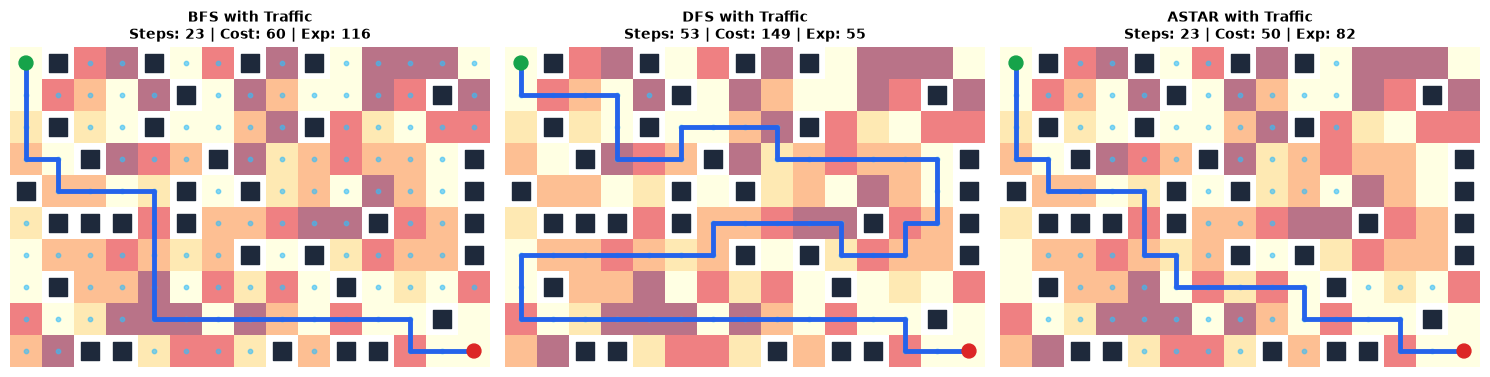

In [11]:
# تصویرسازی مسیرهای یافته‌شده روی نقشه حرارتی ترافیک
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=100)

for ax, name in zip(axes, ["bfs", "dfs", "astar"]):
    p, exp, cost = res_w[name]
    bg = sample_traffic.astype(float).copy()
    bg[sample_grid == 1] = np.nan
    ax.imshow(bg, cmap="YlOrRd", vmin=1, vmax=5, alpha=0.55)
    
    obs_y, obs_x = np.where(sample_grid == 1)
    ax.scatter(obs_x, obs_y, marker='s', color='#1e293b', s=150, label='مانع')
    
    if exp:
        ey = [pt[0] for pt in exp]
        ex = [pt[1] for pt in exp]
        ax.scatter(ex, ey, marker='.', color='#38bdf8', s=40, alpha=0.6, label='گره‌های بازشده')
    if p:
        py = [pt[0] for pt in p]
        px = [pt[1] for pt in p]
        ax.plot(px, py, color='#2563eb', linewidth=3.5, label='مسیر نهایی')
        ax.scatter([px[0], px[-1]], [py[0], py[-1]], color=['#16a34a', '#dc2626'], s=100, zorder=5)
        
    ax.set_title(f"{name.upper()} with Traffic\nSteps: {len(p)-1} | Cost: {cost} | Exp: {len(exp)}", fontsize=10, fontweight='bold')
    ax.axis("off")

plt.tight_layout()
plt.show()

=== نتایج بنچمارک روی ۱۰۰ نقشه با چالش هزینه متغیر معابر ===
       steps   cost  expanded
algo                         
astar  23.97  59.38     96.83
bfs    23.58  69.43    108.92
dfs    32.36  94.60     57.33
تعداد نقشه‌های حل‌پذیر: 72 از ۱۰۰


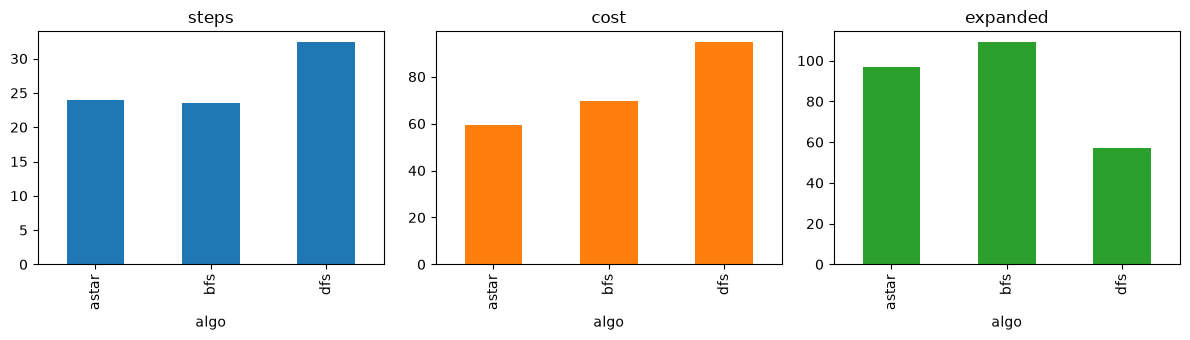

In [12]:
# بنچمارک ۱۰۰ نقشه تصادفی با چالش هزینه متفاوت معابر
bench_rows = []
for seed in range(100):
    g, tr = generate_traffic_environment(seed=seed, wall_prob=WALL_PROB)
    for name in ["bfs", "dfs", "astar"]:
        if name == "astar":
            p, exp, c = astar_weighted(g, tr, START, GOAL)
        else:
            p, exp, c = blind_search_weighted(g, tr, START, GOAL, name)
        if p is not None:
            bench_rows.append({"algo": name, "steps": len(p) - 1, "cost": c, "expanded": len(exp)})

df_w = pd.DataFrame(bench_rows)
summary_w = df_w.groupby("algo")[["steps", "cost", "expanded"]].mean().round(2)
print("=== نتایج بنچمارک روی ۱۰۰ نقشه با چالش هزینه متغیر معابر ===")
print(summary_w)
print(f"تعداد نقشه‌های حل‌پذیر: {len(df_w) // 3} از ۱۰۰")

# نمودار مقایسه‌ای سه گانه
summary_w.plot(kind="bar", subplots=True, layout=(1, 3), figsize=(12, 3.5), legend=False)
plt.tight_layout()
plt.show()